###  **Title: DSC670-T301 Advanced Uses of Generative AI (2271-1)**
####  **Professor:** *Frank Neugebauer*
####  **Date: 26 Sep 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Week3 Exercise : Use the Stable Diffusion API to generate and edit an image.

*************

### Using the Stable Diffusion API for Image Generation and Editing
Stable Diffusion is a text-to-image generative AI model capable of creating realistic and creative images from natural language prompts. In this exercise, the Stable Diffusion API was used within a Jupyter Notebook to generate an original image and then create an edited version using a modified prompt. The objective was to evaluate how effectively the model interpreted text descriptions and transformed them into visual content.
*********
### My Approach
1. Generate one image from a text prompt using the text-to-image endpoint
2. Edit that generated image by passing it back through the image-to-image endpoint with a completely different prompt
3. Compare the original and edited versions and discuss how the model handled the transformation

I chose to generate a golden retriever and then edit it into a robotic mechanical dog. This transformation from a real animal to a futuristic robot version tests how well the model handles converting organic textures (fur, skin) into metallic/mechanical ones while keeping the general pose and setting.
************

### Import Required Libraries


In [27]:
import requests
from PIL import Image
import io
from io import BytesIO
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### Configure API Authentication
The Stability AI API requires an API key for authentication. This is obtained from "https://platform.stability.ai/account/keys"

In [ ]:
STABILITY_API_KEY = ""
if not STABILITY_API_KEY:
    raise RuntimeError("Set STABILITY_API_KEY in your environment before running this notebook.")

# API endpoint
API_HOST = "https://api.stability.ai"

# Headers for API requests
headers = {
    "Authorization": f"Bearer {STABILITY_API_KEY}",
    "Accept": "image/*"
}


### Step 1: Generate the Original Image

The first task is to generate an original image using the Stable Diffusion API. For this exercise, I selected a transformer truck on a beach side scene because it contains multiple visual elements, including beach, truck, lighting effects, and environmental details. Such a prompt allows Stable Diffusion to demonstrate its ability to understand complex descriptions and create detailed images from natural language.

**Prompt**: "A red transformer truck driving along a beautiful beach at sunset, golden waves, palm trees, realistic lighting, highly detailed, cinematic view, with all images have almost equal proportion."
* I selected this prompt because it contains a clear main object, the transformer-style truck, combined with a natural beach environment. The scene is easier to visualize and allows Stable Diffusion to generate recognizable details such as the vehicle, ocean, sunset colors, and surrounding landscape. Compared to a complex futuristic cityscape, this prompt produces a simpler image that makes it easier to observe the effects of image editing in later steps. The combination of a large vehicle and scenic background also demonstrates the model's ability to generate multiple visual elements from a natural language description while maintaining realism and artistic quality.

In [29]:
prompt = """
A giant red transformer-style truck driving along a beautiful 
beach at sunset, golden waves, palm trees, realistic lighting, 
highly detailed, cinematic view, with all images have almost equal proportion
"""
response = requests.post(
"https://api.stability.ai/v2beta/stable-image/generate/core",
headers=headers,
files={"none": ""},
data={
"prompt": prompt,
"output_format": "png"
}
)

if response.status_code == 200:
    with open("original_image.png", "wb") as file:
        file.write(response.content)
    print("Original image generated successfully.")
else:
    raise Exception(str(response.json()))

Original image generated successfully.


### Step 2: Display the Generated Image

The API returns the generated image as raw PNG bytes, which were saved to `original_image.png` in the previous step. To confirm that the request produced the expected result, the saved file is loaded with Pillow and rendered inline using Matplotlib. Displaying the image also allows a visual assessment of how well Stable Diffusion interpreted the prompt in terms of composition, lighting, and level of detail.


Format: PNG
Size: 1536 x 1536 pixels
Mode: RGB


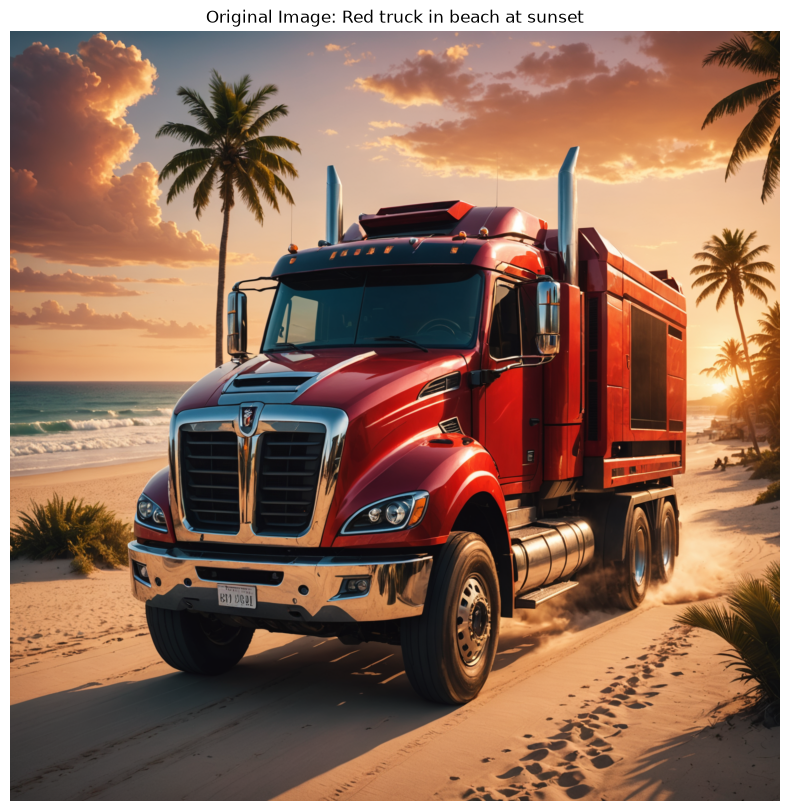

In [30]:
original_image = Image.open("original_image.png")

print(f"Format: {original_image.format}")
print(f"Size: {original_image.size[0]} x {original_image.size[1]} pixels")
print(f"Mode: {original_image.mode}")

plt.figure(figsize=(10, 10))
plt.imshow(original_image)
plt.axis("off")
plt.title("Original Image: Red truck in beach at sunset")
plt.show()


### Observations
The generated image successfully captures most of the key elements specified in the prompt. The red truck is the dominant object in the scene and is positioned prominently in the foreground, making it the focal point of the composition. The AI also accurately incorporated the beach setting, palm trees, ocean waves, and sunset lighting, creating a visually appealing coastal environment.

**Prompt Adherence**
* The truck is rendered in a bright red color as requested.
* The beach environment includes palm trees, sand, water, and a visible sunset.
* The lighting reflects warm golden-hour tones, matching the "sunset" requirement.
* The image exhibits a cinematic perspective with strong depth and visual impact.
* The overall image quality is highly detailed, especially in the truck's reflections, wheels, chrome components, and bodywork.

**Areas Where the Model Differed from the Prompt**
* The truck appears to be a realistic semi-truck rather than a transformer-style vehicle.
* The prompt requested that all elements have "almost equal proportion." 
************

### Step2: Edit the Image
**Edit Prompt:** "The same transformer-style truck parked on the beach during the night, glowing blue lights, starry sky, moonlight reflecting on the ocean, ultra realistic."

I selected this prompt because it introduces several significant visual changes while maintaining the core subject of the image. Specifically, the prompt changes:
* The time of day from sunset to nighttime.
* The lighting conditions from warm golden sunlight to cool blue illumination.
* The truck's activity from driving to being parked.
* The atmosphere from an active beach scene to a calm and peaceful nighttime environment.

This prompt was chosen to test whether Stable Diffusion could maintain image consistency by preserving the truck's appearance while modifying the surrounding environment. Additionally, nighttime scenes provide a good opportunity to evaluate how well the model handles challenging lighting effects such as moonlight, reflections on water, shadows, glowing accents, and star-filled skies.

In [31]:
edit_prompt = """
The same transformer-style truck parked on the beach during the night,
glowing blue lights, starry sky, moonlight reflecting on the ocean,
ultra realistic
"""

# strength controls how much the original image is retained (0 = unchanged, 1 = ignored)
with open("original_image.png", "rb") as source_image:
    edit_response = requests.post(
        "https://api.stability.ai/v2beta/stable-image/generate/sd3",
        headers=headers,
        files={"image": source_image},
        data={
            "prompt": edit_prompt,
            "mode": "image-to-image",
            "strength": 0.65,
            "output_format": "png"
        }
    )

if edit_response.status_code == 200:
    with open("edited_image.png", "wb") as file:
        file.write(edit_response.content)
    print("Edited image generated successfully.")
else:
    raise Exception(str(edit_response.json()))


Edited image generated successfully.


### Step 3: Display the Edited Image

The edited image returned by the image-to-image endpoint was saved as `edited_image.png`. It is loaded and displayed below to verify that the transformation was applied and to evaluate how the model reinterpreted the scene under the new nighttime prompt.


Format: PNG
Size: 1024 x 1024 pixels
Mode: RGB


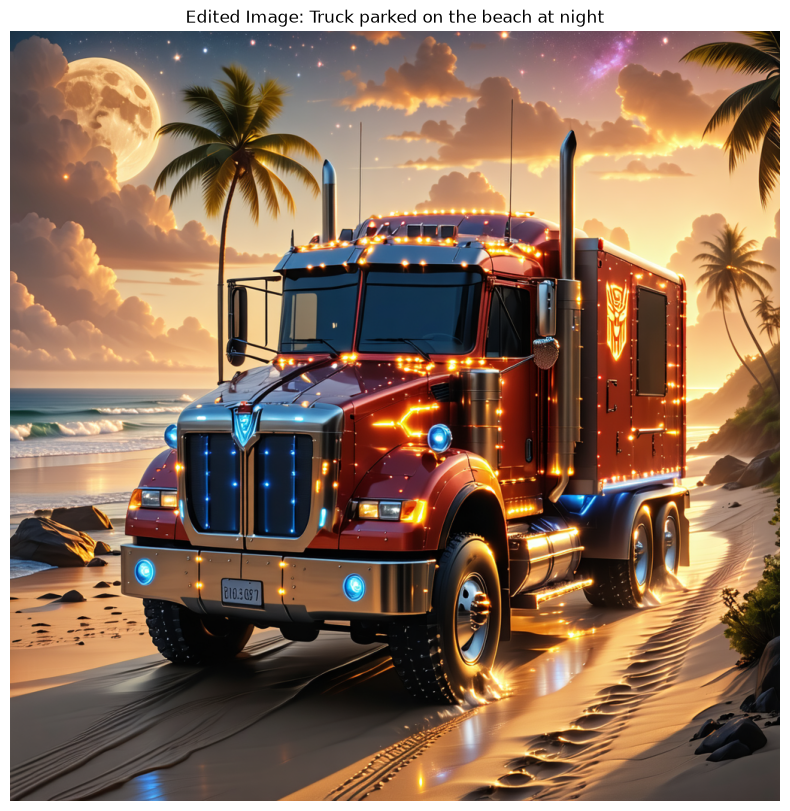

In [32]:
edited_image = Image.open("edited_image.png")

print(f"Format: {edited_image.format}")
print(f"Size: {edited_image.size[0]} x {edited_image.size[1]} pixels")
print(f"Mode: {edited_image.mode}")

plt.figure(figsize=(10, 10))
plt.imshow(edited_image)
plt.axis("off")
plt.title("Edited Image: Truck parked on the beach at night")
plt.show()


### Step 4: Side-by-Side Comparison

Displaying both images together makes it easier to evaluate which elements the model preserved and which it transformed. The comparison below places the original sunset scene next to the edited nighttime version, followed by a summary of average colour and brightness values for each image. These measurements provide objective evidence of the lighting shift, complementing the visual inspection.


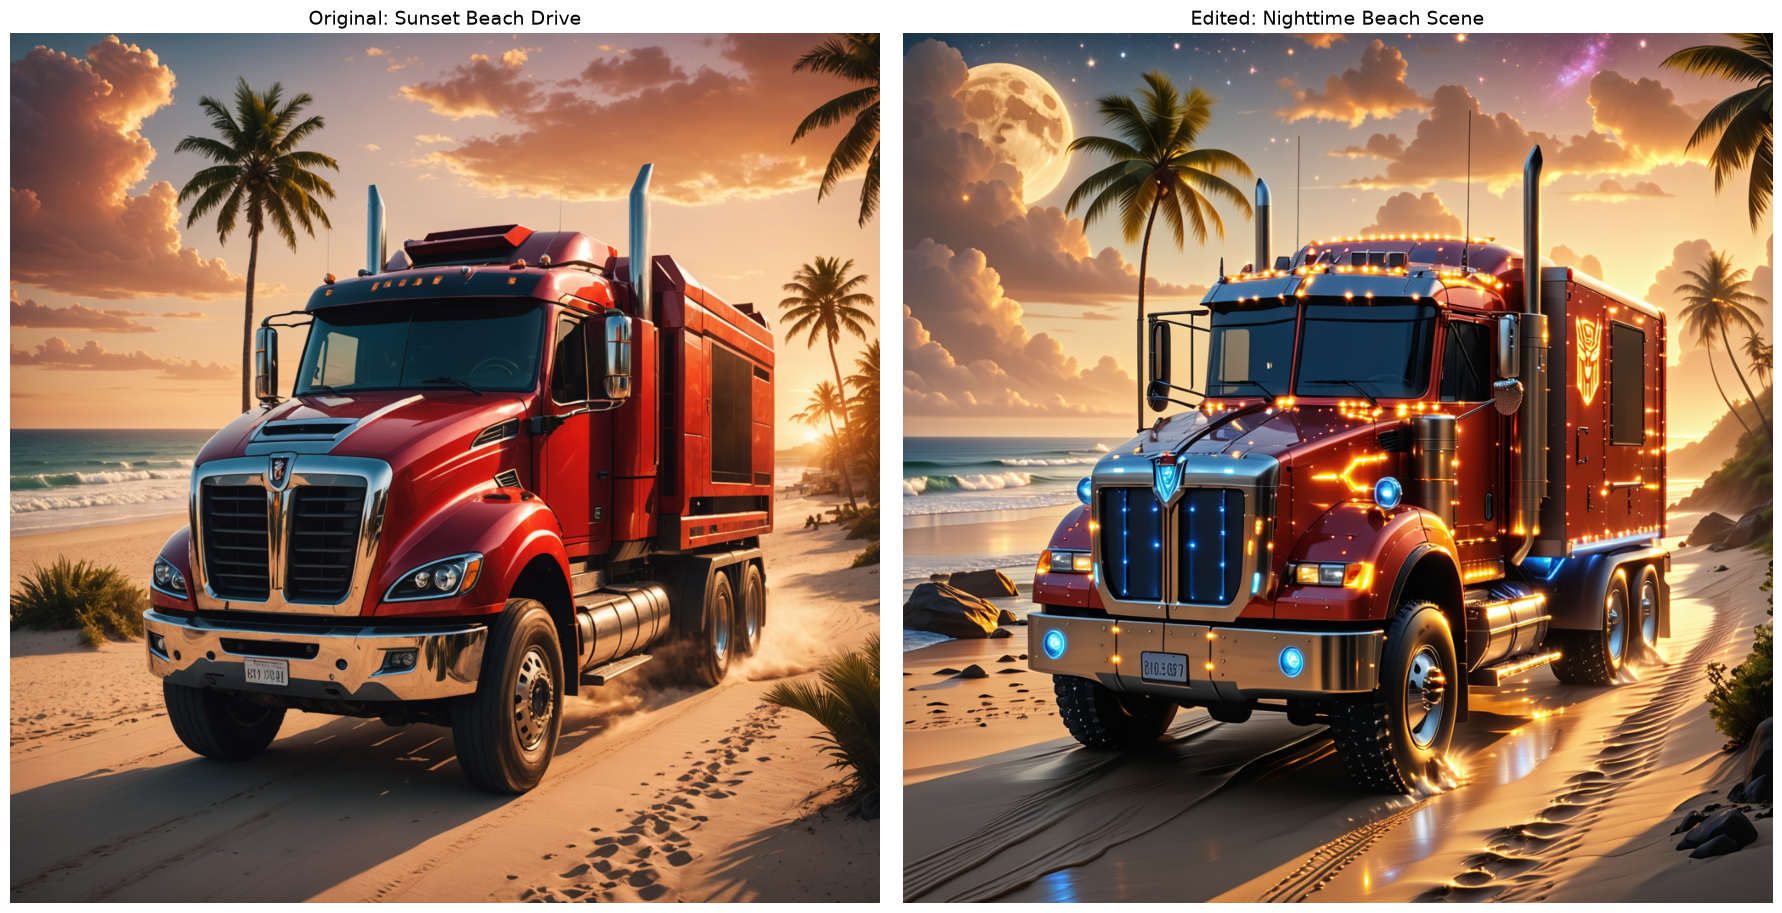

Original  R= 137.8  G=  99.6  B=  79.2  overall brightness= 105.5
Edited    R= 133.6  G= 102.5  B=  80.6  overall brightness= 105.6


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

axes[0].imshow(original_image)
axes[0].set_title("Original: Sunset Beach Drive", fontsize=14)
axes[0].axis("off")

axes[1].imshow(edited_image)
axes[1].set_title("Edited: Nighttime Beach Scene", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

from PIL import ImageStat

for label, image in [("Original", original_image), ("Edited", edited_image)]:
    stats = ImageStat.Stat(image)
    r, g, b = stats.mean
    brightness = sum(stats.mean) / 3
    print(f"{label:<9} R={r:6.1f}  G={g:6.1f}  B={b:6.1f}  overall brightness={brightness:6.1f}")


The side-by-side comparison shows that the image-to-image generation process modified the original image instead of creating a completely new one. The model kept most of the original scene while adding new details based on the edited prompt. The truck, beach, and overall composition remained similar, but several visual elements were changed to match the nighttime and transformer-style requirements.

**Elements Preserved**
* The red truck remained the main subject of the image and stayed in nearly the same position.
* The camera angle remained very similar in both images.
* The beach setting was preserved, including the ocean, waves, sand, and palm trees.
* Major truck features such as the exhaust stacks, windshield, mirrors, wheels, and tank body remained visible.
* The truck continued to have its red color, preserving its overall identity.
* The basic layout of the image remained unchanged, making the edited version recognizable as a modified version of the original image.

**Elements Changed**
* The truck was modified to look more like a transformer-style vehicle with additional mechanical details and a more futuristic appearance.
* Blue glowing lights were added to the truck, including headlights and accent lights.
* Additional decorative lights appeared on various sections of the vehicle.
* The sky changed and included stars and celestial effects.
* The beach environment gained more reflective surfaces, especially on the wet sand.
* Additional landscape details such as rocks and boulders appeared in parts of the scene.

**Areas Where the Edit Did Not Fully Match the Prompt**
* The prompt requested a nighttime scene, but the image still contained some sunset colors and warm lighting.
* The sky appeared to be a mix of sunset and nighttime conditions rather than complete darkness.
* Moonlight reflections were expected on the ocean surface, but the reflections appeared more prominently on the wet sand.
* While the transformer-style appearance improved, some areas of the truck still resembled a traditional semi-truck.
***************

### API Invocation
I found the Stable Diffusion API relatively easy to use. The process required only a few steps: installing the necessary libraries, obtaining an API key, sending a text prompt, and saving the generated image. The API documentation provided clear examples, which made it straightforward to integrate the image generation process into a Jupyter Notebook. One of the most interesting aspects was seeing how a simple text description could be transformed into a detailed visual image within seconds.

The most challenging part was crafting an effective prompt. Small changes in wording significantly affected the final image quality and appearance. For example, adding descriptive terms such as "realistic lighting," "highly detailed," and "cinematic view" produced more visually appealing results. During the image editing phase, I also observed that maintaining consistency between the original and edited images depended heavily on how clearly the modification prompt was written.
******************

### Conclusion

This exercise demonstrated the ability of the Stable Diffusion API to both generate and edit images using natural language prompts. The original image successfully captured the requested beach environment, sunset lighting, and large red truck, producing a visually detailed and realistic scene. The edited image retained many of the original elements while incorporating new features such as transformer-style vehicle details, blue accent lighting, stars, and additional environmental effects.

The comparison showed that image-to-image generation is effective for refining existing images while preserving the overall composition. The model successfully maintained the truck, beach setting, and camera perspective while applying many of the requested modifications. However, some prompt requirements, such as a fully nighttime environment and a completely stationary truck, were only partially achieved. These results highlight the balance that Stable Diffusion maintains between preserving the original image and following new prompt instructions.

The Stable Diffusion API was straightforward to use and produced high-quality results with relatively little code. The exercise demonstrated the power of prompt engineering and image editing in generative AI workflows. It also showed how iterative refinement can improve prompt adherence and create more visually engaging outputs. Stable Diffusion is a valuable tool for artists, developers, researchers, and content creators who wish to rapidly generate and enhance images using artificial intelligence.
***************

### References

Stability AI. (n.d.). Stable Diffusion API Documentation. Retrieved from https://platform.stability.ai/docs

Stability AI. (n.d.). Stable Diffusion Overview. Retrieved from https://stability.ai
